In [1]:
import numpy as np
%pip install lime
import lime
from tokenizers import Tokenizer
from collections import OrderedDict
from datasets import load_dataset
import pandas as pd
import matplotlib.pyplot as plt
import sys
from pathlib import Path
import itertools
from datasets import concatenate_datasets

root = Path.cwd().parent
sys.path.insert(0, str(root))

import Project1


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
from datasets import load_dataset, concatenate_datasets, DatasetDict

topics = ["stance_abortion", "stance_atheism", "stance_climate", "stance_feminist", "stance_hillary"]

per_topic = [load_dataset("cardiffnlp/tweet_eval", t) for t in topics]

# all topics
dataset = DatasetDict({
    split: concatenate_datasets([ds[split] for ds in per_topic])
    for split in ["train", "validation", "test"]
})
# 1 topic
# dataset = per_topic[0]

dataset = dataset.map(lambda x: {"text": x["text"].replace(" #SemST", "")})
# 1 topic
# dataset = load_dataset("cardiffnlp/tweet_eval", topics[0])

In [3]:
# feature representation

class Encoder:

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        raise NotImplementedError("Concrete implementations will be discussed later")

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        raise NotImplementedError("Concrete implementations will be discussed later")

class BagOfWords(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer

    def __len__(self) -> int:
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        vector = np.zeros(len(self))
        for token_id in self.tokenizer.encode(x).ids:
            vector[token_id] += 1
        return vector

class TokenIndicator(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        
    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        unique_token_ids = list(set(self.tokenizer.encode(x).ids))

        # A 0 vector with the same length as the vocabulary except in positions corresponding 
        # to tokens appearing in the document
        vector = np.zeros(len(self))
        vector[unique_token_ids] = 1
        return vector

class tfidf(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        self.dataset = dataset['train']
        self.idf = self._compute_idf()

    def _compute_idf(self) -> 'np.array':
        num_documents = len(self.dataset)
        df = np.zeros(len(self.tokenizer.get_vocab()))

        for example in self.dataset:
            unique_token_ids = set(self.tokenizer.encode(example['text']).ids)
            for token_id in unique_token_ids:
                df[token_id] += 1

        idf = np.log((num_documents + 1) / (df + 1)) + 1
        return idf

    def __len__(self) -> int:
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        tf_vector = np.zeros(len(self))
        token_ids = self.tokenizer.encode(x).ids

        for token_id in token_ids:
            tf_vector[token_id] += 1

        if len(token_ids) > 0:
            tf_vector /= len(token_ids)

        tfidf_vector = tf_vector * self.idf
        return tfidf_vector

In [4]:
#tokenizer
vocab_size = 1000
min_frequency = 2
comb_dataset = concatenate_datasets([dataset["train"], dataset["validation"]])
corpus = [text for text in comb_dataset["text"]]
tokenizer = Project1.experiment.train_tokenizer(corpus, vocab_size, min_frequency)
token_indicator_encoder = TokenIndicator(tokenizer)

In [5]:
# cross-validation
my_seeds = [0]
num_folds = 5
my_cross_validation_sets = []

for seed in my_seeds:  
    my_cross_validation_sets.append(
        Project1.experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(comb_dataset["text"], comb_dataset["label"])), 
            k=num_folds,
            seed=seed
        )
    )

In [6]:
results_folder = Path("./results")
results_folder.mkdir(parents=True, exist_ok=True) 

In [7]:
# classifiers
logistic_model = Project1.loglin.fit(my_cross_validation_sets[0][0]["training"], token_indicator_encoder, save_to=None)



/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [8]:
outcome_space = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])

In [9]:
classifiers = OrderedDict()

In [10]:
token_indicator_encoder = TokenIndicator(tokenizer)
bow_encoder = BagOfWords(tokenizer)
tfidf_encoder = tfidf(tokenizer)

In [11]:
classifiers['logistic_indicator-enc'] = []
for run, seed in enumerate(my_seeds):  # takes about 3 minutes per run (of 5-fold cross validation)
    run_folder = f"{results_folder}/logistic_indicator-enc/seed-{seed}"
    classifiers['logistic_indicator-enc'].append(
        Project1.experiment.cross_validation_experiment(        
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=token_indicator_encoder, 
            model_option='logistic',
            save_to=run_folder,
            loglin_args={
                'max_iter': 100
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklear

In [12]:
classifiers['mlp_indicator-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp_indicator-enc/seed-{seed}"
    classifiers['mlp_indicator-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=token_indicator_encoder,
            model_option='mlp', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.479 seconds
Dataloader done! Time taken: 0.023 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

/home/richard/Documents/NLP1/Projects/NLP1/Project1/smlp.py:68: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:252.)
  indices = torch.tensor([x.row, x.col], dtype=torch.long)
/home/richard/Documents/NLP1/Projects/NLP1/Project1/smlp.py:71: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:848.)
  return torch.sparse_coo_tensor(indices, values, size=x.shape).coalesce()


Epoch 01 | train loss: 1.0514 | train acc: 0.4466 | val loss: 1.0248 | val acc: 0.4751
Epoch 02 | train loss: 0.9301 | train acc: 0.5131 | val loss: 0.9606 | val acc: 0.5300
Epoch 03 | train loss: 0.7690 | train acc: 0.6873 | val loss: 0.9012 | val acc: 0.5678
Epoch 04 | train loss: 0.6016 | train acc: 0.7881 | val loss: 0.9122 | val acc: 0.5678
Epoch 05 | train loss: 0.4759 | train acc: 0.8520 | val loss: 0.9370 | val acc: 0.5763
Epoch 06 | train loss: 0.3753 | train acc: 0.8927 | val loss: 0.9722 | val acc: 0.5815
Epoch 07 | train loss: 0.2949 | train acc: 0.9322 | val loss: 1.0249 | val acc: 0.5780
Epoch 08 | train loss: 0.2329 | train acc: 0.9550 | val loss: 1.0619 | val acc: 0.5986
Epoch 09 | train loss: 0.1842 | train acc: 0.9743 | val loss: 1.1350 | val acc: 0.5849
Epoch 10 | train loss: 0.1454 | train acc: 0.9858 | val loss: 1.1755 | val acc: 0.5883
Epoch 11 | train loss: 0.1142 | train acc: 0.9927 | val loss: 1.2243 | val acc: 0.5866
Epoch 12 | train loss: 0.0914 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0377 | train acc: 0.4698 | val loss: 1.0111 | val acc: 0.4648
Epoch 02 | train loss: 0.8998 | train acc: 0.5603 | val loss: 0.9377 | val acc: 0.5403
Epoch 03 | train loss: 0.7416 | train acc: 0.7104 | val loss: 0.8873 | val acc: 0.6123
Epoch 04 | train loss: 0.5904 | train acc: 0.8095 | val loss: 0.8564 | val acc: 0.6244
Epoch 05 | train loss: 0.4741 | train acc: 0.8524 | val loss: 0.8750 | val acc: 0.6312
Epoch 06 | train loss: 0.3823 | train acc: 0.8966 | val loss: 0.9005 | val acc: 0.6209
Epoch 07 | train loss: 0.3053 | train acc: 0.9245 | val loss: 0.9431 | val acc: 0.6123
Epoch 08 | train loss: 0.2478 | train acc: 0.9494 | val loss: 0.9723 | val acc: 0.6158
Epoch 09 | train loss: 0.1989 | train acc: 0.9657 | val loss: 1.0167 | val acc: 0.6141
Epoch 10 | train loss: 0.1560 | train acc: 0.9824 | val loss: 1.0493 | val acc: 0.6089
Epoch 11 | train loss: 0.1265 | train acc: 0.9901 | val loss: 1.0827 | val acc: 0.6141
Epoch 12 | train loss: 0.1029 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0440 | train acc: 0.4696 | val loss: 1.0234 | val acc: 0.4691
Epoch 02 | train loss: 0.9114 | train acc: 0.5296 | val loss: 0.9543 | val acc: 0.5395
Epoch 03 | train loss: 0.7449 | train acc: 0.7136 | val loss: 0.8974 | val acc: 0.5704
Epoch 04 | train loss: 0.5861 | train acc: 0.8023 | val loss: 0.8925 | val acc: 0.5790
Epoch 05 | train loss: 0.4674 | train acc: 0.8529 | val loss: 0.9086 | val acc: 0.5928
Epoch 06 | train loss: 0.3737 | train acc: 0.8962 | val loss: 0.9390 | val acc: 0.5808
Epoch 07 | train loss: 0.2959 | train acc: 0.9258 | val loss: 0.9721 | val acc: 0.5893
Epoch 08 | train loss: 0.2348 | train acc: 0.9588 | val loss: 1.0131 | val acc: 0.5825
Epoch 09 | train loss: 0.1869 | train acc: 0.9726 | val loss: 1.0645 | val acc: 0.5911
Epoch 10 | train loss: 0.1487 | train acc: 0.9850 | val loss: 1.1090 | val acc: 0.5876
Epoch 11 | train loss: 0.1213 | train acc: 0.9889 | val loss: 1.1627 | val acc: 0.5842
Epoch 12 | train loss: 0.0984 | train acc: 

In [13]:
classifiers['mlp2_indicator-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp2_indicator-enc/seed-{seed}"
    classifiers['mlp2_indicator-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=token_indicator_encoder,
            model_option='mlp2', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.516 seconds
Dataloader done! Time taken: 0.015 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0460 | train acc: 0.4633 | val loss: 1.0182 | val acc: 0.4751
Epoch 02 | train loss: 0.9146 | train acc: 0.5109 | val loss: 0.9308 | val acc: 0.5455
Epoch 03 | train loss: 0.6488 | train acc: 0.7508 | val loss: 0.9818 | val acc: 0.5626
Epoch 04 | train loss: 0.4006 | train acc: 0.8571 | val loss: 1.1327 | val acc: 0.5849
Epoch 05 | train loss: 0.2117 | train acc: 0.9468 | val loss: 1.2798 | val acc: 0.5763
Epoch 06 | train loss: 0.1002 | train acc: 0.9824 | val loss: 1.5050 | val acc: 0.5609
Epoch 07 | train loss: 0.0504 | train acc: 0.9944 | val loss: 1.6637 | val acc: 0.5832
Epoch 08 | train loss: 0.0269 | train acc: 0.9979 | val loss: 1.8214 | val acc: 0.5849
Epoch 09 | train loss: 0.0183 | train acc: 0.9991 | val loss: 1.9068 | val acc: 0.5798
Epoch 10 | train loss: 0.0118 | train acc: 0.9991 | val loss: 2.0363 | val acc: 0.5832
Epoch 11 | train loss: 0.0091 | train acc: 0.9991 | val loss: 2.1326 | val acc: 0.5832
Epoch 12 | train loss: 0.0082 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0551 | train acc: 0.4646 | val loss: 1.0116 | val acc: 0.5026
Epoch 02 | train loss: 0.9212 | train acc: 0.5281 | val loss: 0.9089 | val acc: 0.5609
Epoch 03 | train loss: 0.6350 | train acc: 0.7435 | val loss: 0.9535 | val acc: 0.5815
Epoch 04 | train loss: 0.3713 | train acc: 0.8739 | val loss: 1.0920 | val acc: 0.5643
Epoch 05 | train loss: 0.1927 | train acc: 0.9477 | val loss: 1.3005 | val acc: 0.5729
Epoch 06 | train loss: 0.0912 | train acc: 0.9837 | val loss: 1.4852 | val acc: 0.5763
Epoch 07 | train loss: 0.0433 | train acc: 0.9953 | val loss: 1.6775 | val acc: 0.5746
Epoch 08 | train loss: 0.0240 | train acc: 0.9983 | val loss: 1.8197 | val acc: 0.5678
Epoch 09 | train loss: 0.0181 | train acc: 0.9983 | val loss: 1.9210 | val acc: 0.5746
Epoch 10 | train loss: 0.0153 | train acc: 0.9987 | val loss: 1.9898 | val acc: 0.5626
Epoch 11 | train loss: 0.0107 | train acc: 0.9979 | val loss: 2.0936 | val acc: 0.5678
Epoch 12 | train loss: 0.0133 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0478 | train acc: 0.4732 | val loss: 1.0241 | val acc: 0.4648
Epoch 02 | train loss: 0.9124 | train acc: 0.5242 | val loss: 0.9102 | val acc: 0.5849
Epoch 03 | train loss: 0.6528 | train acc: 0.7362 | val loss: 0.8691 | val acc: 0.6038
Epoch 04 | train loss: 0.3900 | train acc: 0.8653 | val loss: 1.0027 | val acc: 0.6192
Epoch 05 | train loss: 0.1955 | train acc: 0.9489 | val loss: 1.1654 | val acc: 0.6226
Epoch 06 | train loss: 0.0909 | train acc: 0.9811 | val loss: 1.3147 | val acc: 0.6089
Epoch 07 | train loss: 0.0397 | train acc: 0.9961 | val loss: 1.5264 | val acc: 0.6021
Epoch 08 | train loss: 0.0202 | train acc: 0.9991 | val loss: 1.6002 | val acc: 0.6038
Epoch 09 | train loss: 0.0158 | train acc: 0.9983 | val loss: 1.6934 | val acc: 0.6021
Epoch 10 | train loss: 0.0095 | train acc: 0.9996 | val loss: 1.7825 | val acc: 0.6072
Epoch 11 | train loss: 0.0064 | train acc: 0.9991 | val loss: 1.8655 | val acc: 0.6089
Epoch 12 | train loss: 0.0057 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0450 | train acc: 0.4811 | val loss: 1.0303 | val acc: 0.4691
Epoch 02 | train loss: 0.9159 | train acc: 0.5300 | val loss: 0.9468 | val acc: 0.5137
Epoch 03 | train loss: 0.6596 | train acc: 0.7401 | val loss: 0.9531 | val acc: 0.5670
Epoch 04 | train loss: 0.3979 | train acc: 0.8684 | val loss: 1.0216 | val acc: 0.5842
Epoch 05 | train loss: 0.2130 | train acc: 0.9425 | val loss: 1.2155 | val acc: 0.5825
Epoch 06 | train loss: 0.1007 | train acc: 0.9798 | val loss: 1.3599 | val acc: 0.5945
Epoch 07 | train loss: 0.0451 | train acc: 0.9961 | val loss: 1.5257 | val acc: 0.5876
Epoch 08 | train loss: 0.0256 | train acc: 0.9974 | val loss: 1.6821 | val acc: 0.5842
Epoch 09 | train loss: 0.0151 | train acc: 0.9987 | val loss: 1.7788 | val acc: 0.5756
Epoch 10 | train loss: 0.0115 | train acc: 0.9987 | val loss: 1.8679 | val acc: 0.5790
Epoch 11 | train loss: 0.0084 | train acc: 0.9991 | val loss: 1.9382 | val acc: 0.5790
Epoch 12 | train loss: 0.0077 | train acc: 

In [14]:
classifiers['logistic_bow-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/logistic_bow-enc/seed-{seed}"
    classifiers['logistic_bow-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=bow_encoder,
            model_option='logistic',
            save_to=run_folder,
            loglin_args={'max_iter': 100}
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklear

In [15]:
classifiers['mlp_bow-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/mlp_bow-enc/seed-{seed}"
    classifiers['mlp_bow-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=bow_encoder,
            model_option='mlp',
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.499 seconds
Dataloader done! Time taken: 0.015 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0347 | train acc: 0.4698 | val loss: 1.0181 | val acc: 0.4768
Epoch 02 | train loss: 0.8931 | train acc: 0.5568 | val loss: 0.9477 | val acc: 0.5403
Epoch 03 | train loss: 0.7295 | train acc: 0.7293 | val loss: 0.9181 | val acc: 0.5643
Epoch 04 | train loss: 0.5771 | train acc: 0.8027 | val loss: 0.9253 | val acc: 0.5918
Epoch 05 | train loss: 0.4578 | train acc: 0.8576 | val loss: 0.9590 | val acc: 0.5780
Epoch 06 | train loss: 0.3672 | train acc: 0.8932 | val loss: 1.0336 | val acc: 0.5729
Epoch 07 | train loss: 0.2937 | train acc: 0.9288 | val loss: 1.0541 | val acc: 0.5763
Epoch 08 | train loss: 0.2321 | train acc: 0.9580 | val loss: 1.1065 | val acc: 0.5695
Epoch 09 | train loss: 0.1796 | train acc: 0.9768 | val loss: 1.1656 | val acc: 0.5815
Epoch 10 | train loss: 0.1431 | train acc: 0.9837 | val loss: 1.2056 | val acc: 0.5712
Epoch 11 | train loss: 0.1165 | train acc: 0.9914 | val loss: 1.2629 | val acc: 0.5763
Epoch 12 | train loss: 0.0934 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0483 | train acc: 0.4560 | val loss: 0.9900 | val acc: 0.5060
Epoch 02 | train loss: 0.9003 | train acc: 0.5556 | val loss: 0.9250 | val acc: 0.5798
Epoch 03 | train loss: 0.7328 | train acc: 0.7267 | val loss: 0.8725 | val acc: 0.5798
Epoch 04 | train loss: 0.5757 | train acc: 0.8027 | val loss: 0.8901 | val acc: 0.5832
Epoch 05 | train loss: 0.4600 | train acc: 0.8576 | val loss: 0.9190 | val acc: 0.5901
Epoch 06 | train loss: 0.3643 | train acc: 0.9009 | val loss: 0.9605 | val acc: 0.5780
Epoch 07 | train loss: 0.2863 | train acc: 0.9374 | val loss: 1.0076 | val acc: 0.5798
Epoch 08 | train loss: 0.2273 | train acc: 0.9618 | val loss: 1.0599 | val acc: 0.5763
Epoch 09 | train loss: 0.1813 | train acc: 0.9725 | val loss: 1.1086 | val acc: 0.5712
Epoch 10 | train loss: 0.1442 | train acc: 0.9811 | val loss: 1.1543 | val acc: 0.5695
Epoch 11 | train loss: 0.1161 | train acc: 0.9906 | val loss: 1.2010 | val acc: 0.5815
Epoch 12 | train loss: 0.0931 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0372 | train acc: 0.4685 | val loss: 1.0130 | val acc: 0.4666
Epoch 02 | train loss: 0.9026 | train acc: 0.5530 | val loss: 0.9496 | val acc: 0.5369
Epoch 03 | train loss: 0.7391 | train acc: 0.7010 | val loss: 0.8879 | val acc: 0.5969
Epoch 04 | train loss: 0.5842 | train acc: 0.7979 | val loss: 0.8779 | val acc: 0.5969
Epoch 05 | train loss: 0.4643 | train acc: 0.8593 | val loss: 0.9020 | val acc: 0.5952
Epoch 06 | train loss: 0.3646 | train acc: 0.9052 | val loss: 0.9385 | val acc: 0.5866
Epoch 07 | train loss: 0.2899 | train acc: 0.9408 | val loss: 0.9736 | val acc: 0.5986
Epoch 08 | train loss: 0.2289 | train acc: 0.9562 | val loss: 1.0102 | val acc: 0.6003
Epoch 09 | train loss: 0.1823 | train acc: 0.9755 | val loss: 1.0563 | val acc: 0.6072
Epoch 10 | train loss: 0.1401 | train acc: 0.9884 | val loss: 1.0944 | val acc: 0.6021
Epoch 11 | train loss: 0.1159 | train acc: 0.9936 | val loss: 1.1319 | val acc: 0.5901
Epoch 12 | train loss: 0.0942 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0408 | train acc: 0.4747 | val loss: 1.0121 | val acc: 0.4742
Epoch 02 | train loss: 0.9062 | train acc: 0.5532 | val loss: 0.9398 | val acc: 0.5601
Epoch 03 | train loss: 0.7475 | train acc: 0.6973 | val loss: 0.8858 | val acc: 0.6014
Epoch 04 | train loss: 0.5964 | train acc: 0.7920 | val loss: 0.8714 | val acc: 0.6100
Epoch 05 | train loss: 0.4672 | train acc: 0.8568 | val loss: 0.8966 | val acc: 0.5979
Epoch 06 | train loss: 0.3696 | train acc: 0.9048 | val loss: 0.9331 | val acc: 0.6082
Epoch 07 | train loss: 0.2900 | train acc: 0.9391 | val loss: 0.9648 | val acc: 0.6117
Epoch 08 | train loss: 0.2284 | train acc: 0.9623 | val loss: 1.0195 | val acc: 0.6014
Epoch 09 | train loss: 0.1775 | train acc: 0.9747 | val loss: 1.0640 | val acc: 0.6048
Epoch 10 | train loss: 0.1418 | train acc: 0.9884 | val loss: 1.1067 | val acc: 0.6100
Epoch 11 | train loss: 0.1121 | train acc: 0.9923 | val loss: 1.1567 | val acc: 0.6100
Epoch 12 | train loss: 0.0899 | train acc: 

In [16]:
classifiers['mlp2_bow-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp2_bow-enc/seed-{seed}"
    classifiers['mlp2_bow-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=bow_encoder,
            model_option='mlp2', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.514 seconds
Dataloader done! Time taken: 0.015 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0490 | train acc: 0.4663 | val loss: 1.0357 | val acc: 0.4751
Epoch 02 | train loss: 0.9354 | train acc: 0.5054 | val loss: 0.9620 | val acc: 0.5060
Epoch 03 | train loss: 0.6858 | train acc: 0.7147 | val loss: 0.9567 | val acc: 0.5746
Epoch 04 | train loss: 0.4091 | train acc: 0.8567 | val loss: 1.1236 | val acc: 0.5746
Epoch 05 | train loss: 0.2065 | train acc: 0.9425 | val loss: 1.3367 | val acc: 0.5455
Epoch 06 | train loss: 0.0902 | train acc: 0.9846 | val loss: 1.5513 | val acc: 0.5626
Epoch 07 | train loss: 0.0450 | train acc: 0.9970 | val loss: 1.7521 | val acc: 0.5472
Epoch 08 | train loss: 0.0252 | train acc: 0.9979 | val loss: 1.9394 | val acc: 0.5557
Epoch 09 | train loss: 0.0177 | train acc: 0.9974 | val loss: 2.0677 | val acc: 0.5420
Epoch 10 | train loss: 0.0165 | train acc: 0.9987 | val loss: 2.1467 | val acc: 0.5523
Epoch 11 | train loss: 0.0082 | train acc: 0.9987 | val loss: 2.2324 | val acc: 0.5472
Epoch 12 | train loss: 0.0128 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0468 | train acc: 0.4637 | val loss: 0.9993 | val acc: 0.5026
Epoch 02 | train loss: 0.9123 | train acc: 0.5260 | val loss: 0.8895 | val acc: 0.5815
Epoch 03 | train loss: 0.6386 | train acc: 0.7473 | val loss: 0.9329 | val acc: 0.5832
Epoch 04 | train loss: 0.3716 | train acc: 0.8769 | val loss: 1.0994 | val acc: 0.5849
Epoch 05 | train loss: 0.1888 | train acc: 0.9524 | val loss: 1.2553 | val acc: 0.5695
Epoch 06 | train loss: 0.0867 | train acc: 0.9854 | val loss: 1.4493 | val acc: 0.5815
Epoch 07 | train loss: 0.0443 | train acc: 0.9949 | val loss: 1.5954 | val acc: 0.5798
Epoch 08 | train loss: 0.0257 | train acc: 0.9983 | val loss: 1.7387 | val acc: 0.5746
Epoch 09 | train loss: 0.0156 | train acc: 0.9983 | val loss: 1.8433 | val acc: 0.5780
Epoch 10 | train loss: 0.0121 | train acc: 0.9983 | val loss: 1.9518 | val acc: 0.5780
Epoch 11 | train loss: 0.0128 | train acc: 0.9991 | val loss: 2.0125 | val acc: 0.5832
Epoch 12 | train loss: 0.0078 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0506 | train acc: 0.4676 | val loss: 1.0270 | val acc: 0.4648
Epoch 02 | train loss: 0.9310 | train acc: 0.5088 | val loss: 0.9380 | val acc: 0.5403
Epoch 03 | train loss: 0.6924 | train acc: 0.7143 | val loss: 0.9673 | val acc: 0.6003
Epoch 04 | train loss: 0.4449 | train acc: 0.8361 | val loss: 1.0166 | val acc: 0.5952
Epoch 05 | train loss: 0.2357 | train acc: 0.9395 | val loss: 1.1713 | val acc: 0.5883
Epoch 06 | train loss: 0.1108 | train acc: 0.9807 | val loss: 1.3213 | val acc: 0.5952
Epoch 07 | train loss: 0.0527 | train acc: 0.9953 | val loss: 1.4815 | val acc: 0.5866
Epoch 08 | train loss: 0.0287 | train acc: 0.9983 | val loss: 1.6236 | val acc: 0.5866
Epoch 09 | train loss: 0.0167 | train acc: 0.9991 | val loss: 1.7362 | val acc: 0.5952
Epoch 10 | train loss: 0.0124 | train acc: 0.9991 | val loss: 1.8645 | val acc: 0.6038
Epoch 11 | train loss: 0.0106 | train acc: 0.9987 | val loss: 1.9051 | val acc: 0.6038
Epoch 12 | train loss: 0.0093 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0434 | train acc: 0.4773 | val loss: 1.0268 | val acc: 0.4691
Epoch 02 | train loss: 0.9076 | train acc: 0.5532 | val loss: 0.9439 | val acc: 0.5052
Epoch 03 | train loss: 0.6317 | train acc: 0.7496 | val loss: 0.9370 | val acc: 0.5790
Epoch 04 | train loss: 0.3654 | train acc: 0.8799 | val loss: 1.0515 | val acc: 0.6082
Epoch 05 | train loss: 0.1768 | train acc: 0.9528 | val loss: 1.2376 | val acc: 0.5911
Epoch 06 | train loss: 0.0823 | train acc: 0.9880 | val loss: 1.4288 | val acc: 0.5756
Epoch 07 | train loss: 0.0393 | train acc: 0.9957 | val loss: 1.5624 | val acc: 0.5808
Epoch 08 | train loss: 0.0239 | train acc: 0.9979 | val loss: 1.7021 | val acc: 0.5739
Epoch 09 | train loss: 0.0140 | train acc: 0.9987 | val loss: 1.7932 | val acc: 0.5756
Epoch 10 | train loss: 0.0105 | train acc: 0.9996 | val loss: 1.8851 | val acc: 0.5756
Epoch 11 | train loss: 0.0088 | train acc: 0.9991 | val loss: 1.9262 | val acc: 0.5687
Epoch 12 | train loss: 0.0063 | train acc: 

In [17]:
classifiers['logistic_tfidf-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/logistic_tfidf-enc/seed-{seed}"
    classifiers['logistic_tfidf-enc'].append(
        Project1.experiment.cross_validation_experiment(        
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=tfidf_encoder, 
            model_option='logistic',
            save_to=run_folder,
            loglin_args={
                'max_iter': 100
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, catego

In [18]:
classifiers['mlp_tfidf-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/mlp_tfidf-enc/seed-{seed}"
    classifiers['mlp_tfidf-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=tfidf(tokenizer),
            model_option='mlp', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.522 seconds
Dataloader done! Time taken: 0.014 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0750 | train acc: 0.4607 | val loss: 1.0480 | val acc: 0.4751
Epoch 02 | train loss: 1.0209 | train acc: 0.4796 | val loss: 1.0229 | val acc: 0.4751
Epoch 03 | train loss: 0.9635 | train acc: 0.4908 | val loss: 0.9822 | val acc: 0.4906
Epoch 04 | train loss: 0.8705 | train acc: 0.5869 | val loss: 0.9360 | val acc: 0.5506
Epoch 05 | train loss: 0.7670 | train acc: 0.7181 | val loss: 0.9028 | val acc: 0.5712
Epoch 06 | train loss: 0.6810 | train acc: 0.7636 | val loss: 0.8941 | val acc: 0.5832
Epoch 07 | train loss: 0.6091 | train acc: 0.7902 | val loss: 0.8966 | val acc: 0.5866
Epoch 08 | train loss: 0.5586 | train acc: 0.7997 | val loss: 0.9064 | val acc: 0.5866
Epoch 09 | train loss: 0.5162 | train acc: 0.8181 | val loss: 0.9240 | val acc: 0.5815
Epoch 10 | train loss: 0.4775 | train acc: 0.8387 | val loss: 0.9474 | val acc: 0.5832
Epoch 11 | train loss: 0.4478 | train acc: 0.8456 | val loss: 0.9635 | val acc: 0.5832
Epoch 12 | train loss: 0.4200 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0815 | train acc: 0.4024 | val loss: 1.0319 | val acc: 0.5026
Epoch 02 | train loss: 1.0209 | train acc: 0.4728 | val loss: 1.0006 | val acc: 0.5026
Epoch 03 | train loss: 0.9670 | train acc: 0.4822 | val loss: 0.9635 | val acc: 0.5352
Epoch 04 | train loss: 0.8837 | train acc: 0.5783 | val loss: 0.9158 | val acc: 0.5763
Epoch 05 | train loss: 0.7849 | train acc: 0.7006 | val loss: 0.8880 | val acc: 0.5935
Epoch 06 | train loss: 0.6983 | train acc: 0.7495 | val loss: 0.8819 | val acc: 0.5763
Epoch 07 | train loss: 0.6290 | train acc: 0.7846 | val loss: 0.8714 | val acc: 0.5883
Epoch 08 | train loss: 0.5729 | train acc: 0.8057 | val loss: 0.8843 | val acc: 0.5815
Epoch 09 | train loss: 0.5324 | train acc: 0.8194 | val loss: 0.9062 | val acc: 0.5901
Epoch 10 | train loss: 0.4977 | train acc: 0.8267 | val loss: 0.9273 | val acc: 0.5832
Epoch 11 | train loss: 0.4608 | train acc: 0.8447 | val loss: 0.9543 | val acc: 0.5695
Epoch 12 | train loss: 0.4393 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0730 | train acc: 0.4427 | val loss: 1.0501 | val acc: 0.4648
Epoch 02 | train loss: 1.0168 | train acc: 0.4822 | val loss: 1.0254 | val acc: 0.4648
Epoch 03 | train loss: 0.9621 | train acc: 0.4878 | val loss: 0.9880 | val acc: 0.4734
Epoch 04 | train loss: 0.8811 | train acc: 0.5650 | val loss: 0.9365 | val acc: 0.5660
Epoch 05 | train loss: 0.7893 | train acc: 0.6808 | val loss: 0.8962 | val acc: 0.6055
Epoch 06 | train loss: 0.7018 | train acc: 0.7435 | val loss: 0.8751 | val acc: 0.6072
Epoch 07 | train loss: 0.6354 | train acc: 0.7739 | val loss: 0.8699 | val acc: 0.5969
Epoch 08 | train loss: 0.5818 | train acc: 0.7962 | val loss: 0.8674 | val acc: 0.6038
Epoch 09 | train loss: 0.5392 | train acc: 0.8065 | val loss: 0.8814 | val acc: 0.6021
Epoch 10 | train loss: 0.5026 | train acc: 0.8224 | val loss: 0.8950 | val acc: 0.5935
Epoch 11 | train loss: 0.4706 | train acc: 0.8370 | val loss: 0.9143 | val acc: 0.6021
Epoch 12 | train loss: 0.4391 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0668 | train acc: 0.4811 | val loss: 1.0492 | val acc: 0.4691
Epoch 02 | train loss: 1.0207 | train acc: 0.4811 | val loss: 1.0260 | val acc: 0.4691
Epoch 03 | train loss: 0.9656 | train acc: 0.4893 | val loss: 0.9874 | val acc: 0.4742
Epoch 04 | train loss: 0.8759 | train acc: 0.5879 | val loss: 0.9383 | val acc: 0.5447
Epoch 05 | train loss: 0.7772 | train acc: 0.7015 | val loss: 0.9122 | val acc: 0.6014
Epoch 06 | train loss: 0.6971 | train acc: 0.7500 | val loss: 0.8946 | val acc: 0.5911
Epoch 07 | train loss: 0.6241 | train acc: 0.7740 | val loss: 0.8990 | val acc: 0.5979
Epoch 08 | train loss: 0.5750 | train acc: 0.7976 | val loss: 0.9036 | val acc: 0.5859
Epoch 09 | train loss: 0.5300 | train acc: 0.8113 | val loss: 0.9217 | val acc: 0.5928
Epoch 10 | train loss: 0.4944 | train acc: 0.8272 | val loss: 0.9405 | val acc: 0.5928
Epoch 11 | train loss: 0.4591 | train acc: 0.8486 | val loss: 0.9648 | val acc: 0.5911
Epoch 12 | train loss: 0.4332 | train acc: 

In [19]:
classifiers['mlp2_tfidf-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp2_tfidf-enc/seed-{seed}"
    classifiers['mlp2_tfidf-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=bow_encoder,
            model_option='mlp2', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.512 seconds
Dataloader done! Time taken: 0.014 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0464 | train acc: 0.4655 | val loss: 1.0266 | val acc: 0.4751
Epoch 02 | train loss: 0.9208 | train acc: 0.5242 | val loss: 0.9407 | val acc: 0.5300
Epoch 03 | train loss: 0.6556 | train acc: 0.7392 | val loss: 0.9469 | val acc: 0.5712
Epoch 04 | train loss: 0.3776 | train acc: 0.8696 | val loss: 1.1228 | val acc: 0.5746
Epoch 05 | train loss: 0.1917 | train acc: 0.9532 | val loss: 1.2785 | val acc: 0.5678
Epoch 06 | train loss: 0.0812 | train acc: 0.9888 | val loss: 1.4833 | val acc: 0.5678
Epoch 07 | train loss: 0.0417 | train acc: 0.9944 | val loss: 1.6463 | val acc: 0.5557
Epoch 08 | train loss: 0.0259 | train acc: 0.9974 | val loss: 1.7926 | val acc: 0.5678
Epoch 09 | train loss: 0.0144 | train acc: 0.9991 | val loss: 1.8778 | val acc: 0.5575
Epoch 10 | train loss: 0.0131 | train acc: 0.9983 | val loss: 1.9619 | val acc: 0.5609
Epoch 11 | train loss: 0.0093 | train acc: 0.9987 | val loss: 2.0326 | val acc: 0.5626
Epoch 12 | train loss: 0.0082 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0524 | train acc: 0.4685 | val loss: 1.0083 | val acc: 0.5026
Epoch 02 | train loss: 0.9171 | train acc: 0.5161 | val loss: 0.9096 | val acc: 0.5489
Epoch 03 | train loss: 0.6346 | train acc: 0.7529 | val loss: 0.9676 | val acc: 0.5712
Epoch 04 | train loss: 0.3700 | train acc: 0.8769 | val loss: 1.1275 | val acc: 0.5626
Epoch 05 | train loss: 0.1888 | train acc: 0.9550 | val loss: 1.3402 | val acc: 0.5660
Epoch 06 | train loss: 0.0852 | train acc: 0.9888 | val loss: 1.5442 | val acc: 0.5592
Epoch 07 | train loss: 0.0420 | train acc: 0.9953 | val loss: 1.7198 | val acc: 0.5695
Epoch 08 | train loss: 0.0230 | train acc: 0.9987 | val loss: 1.8746 | val acc: 0.5592
Epoch 09 | train loss: 0.0165 | train acc: 0.9991 | val loss: 1.9892 | val acc: 0.5540
Epoch 10 | train loss: 0.0144 | train acc: 0.9983 | val loss: 2.0817 | val acc: 0.5523
Epoch 11 | train loss: 0.0123 | train acc: 0.9983 | val loss: 2.1660 | val acc: 0.5489
Epoch 12 | train loss: 0.0081 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0460 | train acc: 0.4749 | val loss: 1.0293 | val acc: 0.4648
Epoch 02 | train loss: 0.9247 | train acc: 0.5092 | val loss: 0.9486 | val acc: 0.5575
Epoch 03 | train loss: 0.6576 | train acc: 0.7353 | val loss: 0.9435 | val acc: 0.5798
Epoch 04 | train loss: 0.3795 | train acc: 0.8670 | val loss: 1.0674 | val acc: 0.5883
Epoch 05 | train loss: 0.1841 | train acc: 0.9580 | val loss: 1.2892 | val acc: 0.5832
Epoch 06 | train loss: 0.0791 | train acc: 0.9914 | val loss: 1.5222 | val acc: 0.5935
Epoch 07 | train loss: 0.0366 | train acc: 0.9979 | val loss: 1.6449 | val acc: 0.5866
Epoch 08 | train loss: 0.0211 | train acc: 0.9974 | val loss: 1.7511 | val acc: 0.5986
Epoch 09 | train loss: 0.0130 | train acc: 0.9996 | val loss: 1.8246 | val acc: 0.5815
Epoch 10 | train loss: 0.0116 | train acc: 0.9983 | val loss: 1.9028 | val acc: 0.5798
Epoch 11 | train loss: 0.0079 | train acc: 0.9991 | val loss: 1.9856 | val acc: 0.5815
Epoch 12 | train loss: 0.0070 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0493 | train acc: 0.4623 | val loss: 1.0273 | val acc: 0.4691
Epoch 02 | train loss: 0.9343 | train acc: 0.5167 | val loss: 0.9573 | val acc: 0.5017
Epoch 03 | train loss: 0.7023 | train acc: 0.7110 | val loss: 0.9231 | val acc: 0.5670
Epoch 04 | train loss: 0.4198 | train acc: 0.8589 | val loss: 1.0080 | val acc: 0.5893
Epoch 05 | train loss: 0.2059 | train acc: 0.9477 | val loss: 1.1502 | val acc: 0.6031
Epoch 06 | train loss: 0.0876 | train acc: 0.9876 | val loss: 1.3191 | val acc: 0.5979
Epoch 07 | train loss: 0.0428 | train acc: 0.9966 | val loss: 1.4784 | val acc: 0.6014
Epoch 08 | train loss: 0.0248 | train acc: 0.9974 | val loss: 1.5974 | val acc: 0.5825
Epoch 09 | train loss: 0.0138 | train acc: 0.9991 | val loss: 1.6913 | val acc: 0.5997
Epoch 10 | train loss: 0.0096 | train acc: 0.9983 | val loss: 1.7552 | val acc: 0.5962
Epoch 11 | train loss: 0.0078 | train acc: 0.9996 | val loss: 1.8203 | val acc: 0.5979
Epoch 12 | train loss: 0.0080 | train acc: 

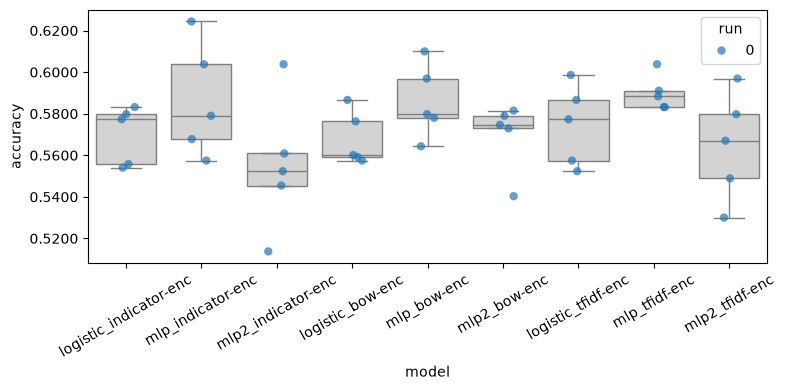

In [20]:
Project1.analysis.plot_box_and_points(Project1.analysis.make_data_frame(classifiers))

In [21]:
def get_all_measurements_for(data, sys_name):
    return np.array([list(run_data['accuracies'].values()) for run_data in data[sys_name]])


A = logistic_indicator-enc, B = mlp_indicator-enc
P(A wins) = 0.0701
P(Tie)    = 0.1210
P(B wins) = 0.8088
Effect Size = 1.41

A = logistic_indicator-enc, B = mlp2_indicator-enc
P(A wins) = 0.6547
P(Tie)    = 0.1277
P(B wins) = 0.2177
Effect Size = -0.65

A = mlp_indicator-enc, B = mlp2_indicator-enc
P(A wins) = 0.8880
P(Tie)    = 0.0530
P(B wins) = 0.0591
Effect Size = -1.71


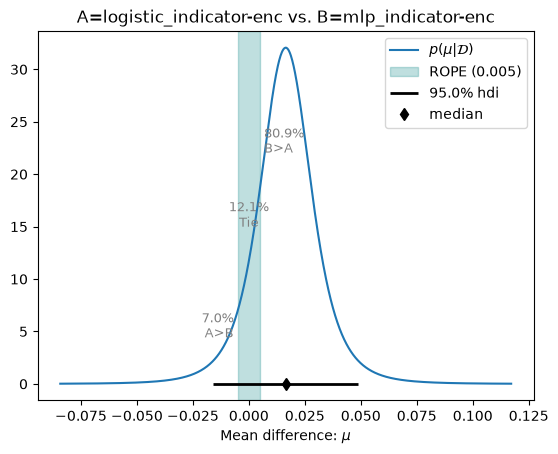

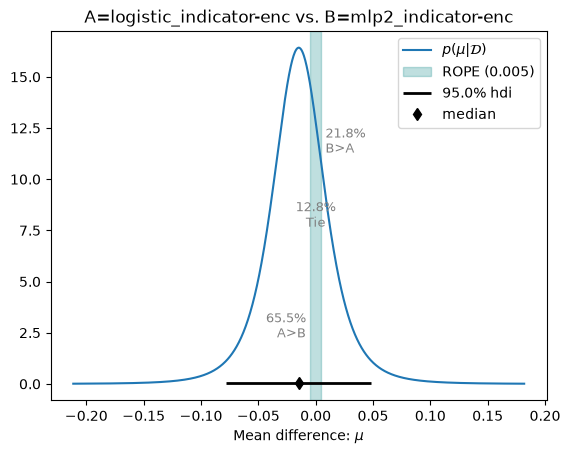

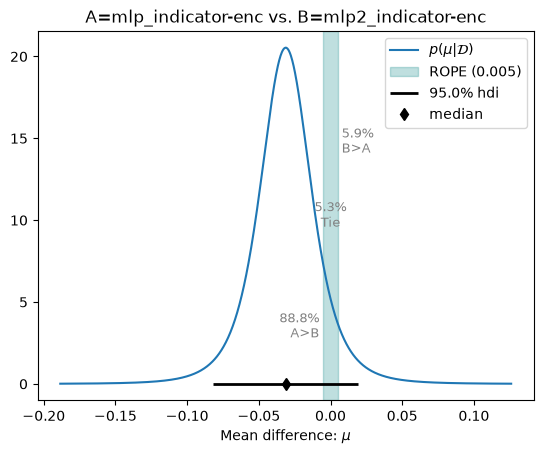

In [22]:
models = {
    "logistic_indicator-enc": get_all_measurements_for(
        classifiers, "logistic_indicator-enc"
    ).flatten(),

    "mlp_indicator-enc": get_all_measurements_for(
        classifiers, "mlp_indicator-enc"
    ).flatten(),

    "mlp2_indicator-enc": get_all_measurements_for(
        classifiers, "mlp2_indicator-enc"
    ).flatten()
}

rope = 0.005

# Compare every pair of models
for name_a, name_b in itertools.combinations(models.keys(), 2):

    posterior = Project1.analysis.BenavoliCorrelatedT(
        models[name_a],
        models[name_b],
        names=[name_a, name_b]
    )

    p_a, p_tie, p_b = posterior.probs(rope)

    print(f"\nA = {name_a}, B = {name_b}")
    print(f"P(A wins) = {p_a:.4f}")
    print(f"P(Tie)    = {p_tie:.4f}")
    print(f"P(B wins) = {p_b:.4f}")
    print(f"Effect Size = {posterior.effect_size:.2f}")

    _ = posterior.plot(rope)

In [23]:

from pathlib import Path
import Project1.smlp as smlp
import Project1.smlp2 as smlp2

# Find saved checkpoints from your cross-validation
def find_checkpoints(model_name):
    folder = results_folder / model_name / "seed-0"

    checkpoints = sorted(
        path.with_suffix("")
        for path in folder.rglob("*.pt")
        if path.with_suffix(".json").exists()
    )

    if not checkpoints:
        raise FileNotFoundError(
            f"No saved model checkpoints found in {folder}"
        )

    return checkpoints


mlp_checkpoints = find_checkpoints("mlp_indicator-enc")
mlp2_checkpoints = find_checkpoints("mlp2_indicator-enc")

print("Original MLP checkpoints:")
for i, path in enumerate(mlp_checkpoints):
    print(i, path)

print("\nModified MLP checkpoints:")
for i, path in enumerate(mlp2_checkpoints):
    print(i, path)


Original MLP checkpoints:
0 results/mlp_indicator-enc/seed-0/fold-0/model
1 results/mlp_indicator-enc/seed-0/fold-1/model
2 results/mlp_indicator-enc/seed-0/fold-2/model
3 results/mlp_indicator-enc/seed-0/fold-3/model
4 results/mlp_indicator-enc/seed-0/fold-4/model

Modified MLP checkpoints:
0 results/mlp2_indicator-enc/seed-0/fold-0/model
1 results/mlp2_indicator-enc/seed-0/fold-1/model
2 results/mlp2_indicator-enc/seed-0/fold-2/model
3 results/mlp2_indicator-enc/seed-0/fold-3/model
4 results/mlp2_indicator-enc/seed-0/fold-4/model


In [24]:
# Select corresponding checkpoints from the same fold
fold = 0

mlp_model = smlp.load(
    str(mlp_checkpoints[fold]),
    device="cpu"
)

mlp2_model = smlp2.load2(
    str(mlp2_checkpoints[fold]),
    device="cpu"
)

mlp_model.eval()
mlp2_model.eval()

print("Both MLP models loaded successfully!")

Both MLP models loaded successfully!


In [25]:
# Log-linear
def logistic_predict(texts):
    return Project1.loglin.predict_probs(
        texts,
        logistic_model,
        token_indicator_encoder
    )

# Original MLP
def mlp_predict(texts):
    return Project1.smlp.predict_probs(
        texts,
        mlp_model,
        token_indicator_encoder
    )

# Modified MLP (two hidden layers)
def mlp2_predict(texts):
    return Project1.smlp2.predict_probs2(
        texts,
        mlp2_model,
        token_indicator_encoder
    )

# Models for LIME
models = {
    "Log-linear": logistic_predict,
    "Original MLP": mlp_predict,
    "Modified MLP": mlp2_predict
}

In [26]:
tweet_id = 157
test_text = dataset["test"][tweet_id]
print(test_text)
print("Original MLP:", mlp_predict(test_text))
print("Modified MLP:", mlp2_predict(test_text))
print("Log-linear:", logistic_predict(test_text))

{'text': 'What about in cases of rape', 'label': 2}
Original MLP: [[0.3358358  0.32805955 0.33610463]
 [0.3027471  0.3390019  0.35825095]]
Modified MLP: [[0.33540648 0.34693244 0.31766108]
 [0.2940712  0.3597269  0.34620196]]
Log-linear: [[0.47059944 0.27279933 0.25660123]
 [0.28073599 0.21958474 0.49967927]]



Tweet 1: Where is the childcare program @user which you said would be in place? #loneparents #7istooyoung
True class: against

--- Log-linear ---
Prediction: against
Probabilities: [0.2963 0.585  0.1187]
Explanation: [(np.str_('7istooyoung'), 0.30217625324109476), (np.str_('loneparents'), 0.29607064546033945), (np.str_('place'), -0.2418375395095965), (np.str_('user'), -0.19186145262417534), (np.str_('would'), -0.15516353139497574), (np.str_('childcare'), 0.13137936259190103), (np.str_('be'), 0.08889178758906915), (np.str_('program'), -0.08841922609830585), (np.str_('in'), 0.06260378024914036), (np.str_('Where'), -0.05503145619210945)]


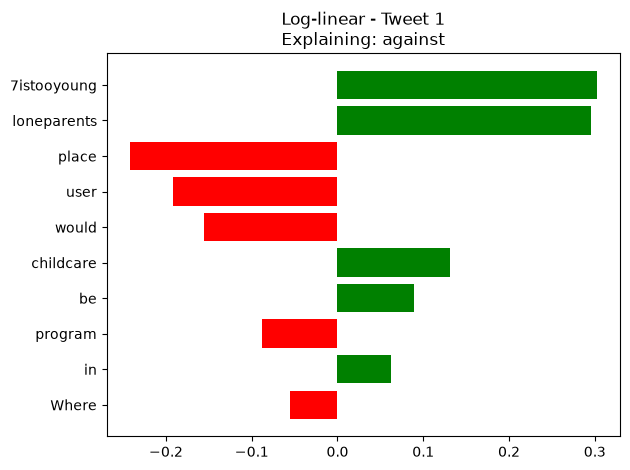


--- Original MLP ---
Prediction: against
Probabilities: [0.3263 0.5453 0.1284]
Explanation: [(np.str_('loneparents'), 0.145281585871067), (np.str_('7istooyoung'), 0.08960855094787039), (np.str_('place'), -0.08530866303078195), (np.str_('program'), -0.05967707834859598), (np.str_('the'), 0.05073073679624705), (np.str_('be'), 0.04478320641999866), (np.str_('you'), 0.03136320432451416), (np.str_('user'), -0.031160824496997662), (np.str_('childcare'), 0.03044785336924891), (np.str_('which'), -0.023636316519945785)]


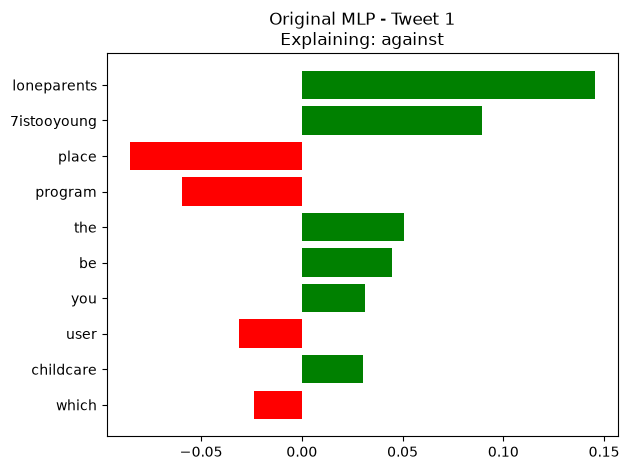


--- Modified MLP ---
Prediction: against
Probabilities: [0.2197 0.5076 0.2727]
Explanation: [(np.str_('loneparents'), 0.0886325890633487), (np.str_('7istooyoung'), 0.08299924317006205), (np.str_('place'), -0.060897486754153865), (np.str_('program'), -0.04474342774837657), (np.str_('childcare'), 0.043025170937551295), (np.str_('Where'), -0.034375559448058014), (np.str_('be'), 0.03359812026773952), (np.str_('the'), 0.032878755316580376), (np.str_('you'), 0.020652717157433765), (np.str_('which'), -0.016989044239073294)]


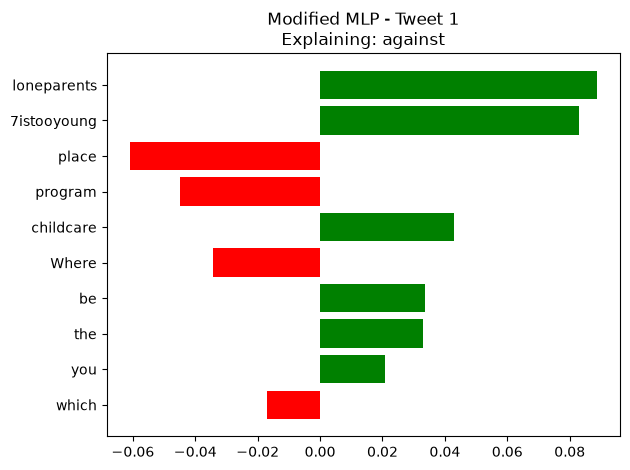


Tweet 8: Pray for the Navy yard. God please keep the casualties minimal.   #1A #2A #NRA #COS #CCOT #TGDN #PJNET  #WAKEUPAMERICA
True class: against

--- Log-linear ---
Prediction: against
Probabilities: [0.005 0.995 0.   ]
Explanation: [(np.str_('God'), 0.1429080983757843), (np.str_('please'), 0.11685828531396887), (np.str_('NRA'), 0.05202656976386847), (np.str_('TGDN'), -0.04991149827194891), (np.str_('casualties'), 0.048519856314219074), (np.str_('yard'), -0.04029877916860328), (np.str_('CCOT'), 0.03325728870642237), (np.str_('PJNET'), -0.019922736819905213), (np.str_('2A'), 0.018168784619347976), (np.str_('1A'), -0.01526801061270719)]


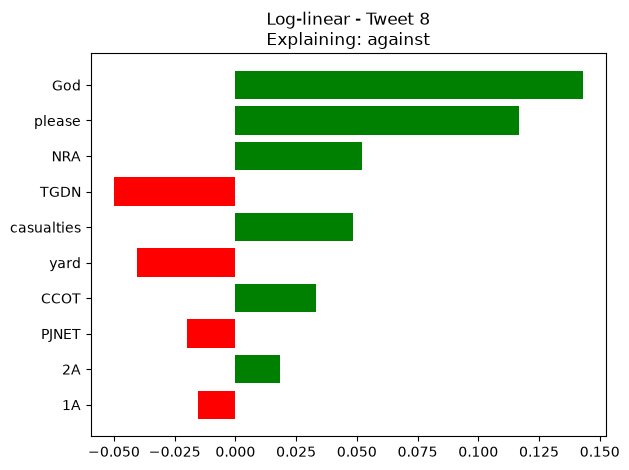


--- Original MLP ---
Prediction: against
Probabilities: [0.1319 0.8499 0.0182]
Explanation: [(np.str_('God'), 0.11425217866949533), (np.str_('please'), 0.0953262221514305), (np.str_('casualties'), 0.0951682394694503), (np.str_('WAKEUPAMERICA'), -0.0543328183321768), (np.str_('COS'), 0.04349465270452427), (np.str_('yard'), -0.037260927872917744), (np.str_('the'), 0.03605457043528477), (np.str_('PJNET'), 0.03443876237202263), (np.str_('NRA'), 0.02941864504656658), (np.str_('CCOT'), 0.028186668076503583)]


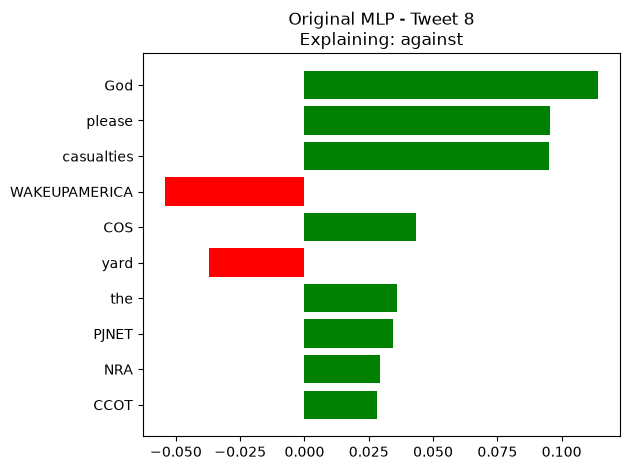


--- Modified MLP ---
Prediction: against
Probabilities: [0.12   0.8061 0.0739]
Explanation: [(np.str_('please'), 0.10413034502567327), (np.str_('God'), 0.09364787982464651), (np.str_('casualties'), 0.0672955861168462), (np.str_('PJNET'), 0.051313238550329765), (np.str_('the'), 0.044015501311596664), (np.str_('TGDN'), -0.04186259878689003), (np.str_('yard'), -0.03949084032791494), (np.str_('CCOT'), 0.033656860449001964), (np.str_('COS'), 0.03322723239661496), (np.str_('WAKEUPAMERICA'), -0.027625788381503195)]


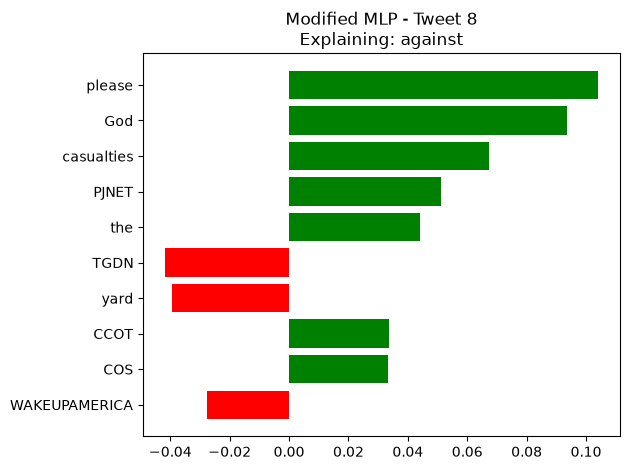


Tweet 157: What about in cases of rape
True class: favor

--- Log-linear ---
Prediction: favor
Probabilities: [0.259  0.1595 0.5814]
Explanation: [(np.str_('What'), 0.19794821962031348), (np.str_('cases'), 0.1745221435167502), (np.str_('about'), -0.09851023386183039), (np.str_('in'), 0.04754460486481241), (np.str_('of'), -0.04655705747705745), (np.str_('rape'), 0.020841362810956245)]


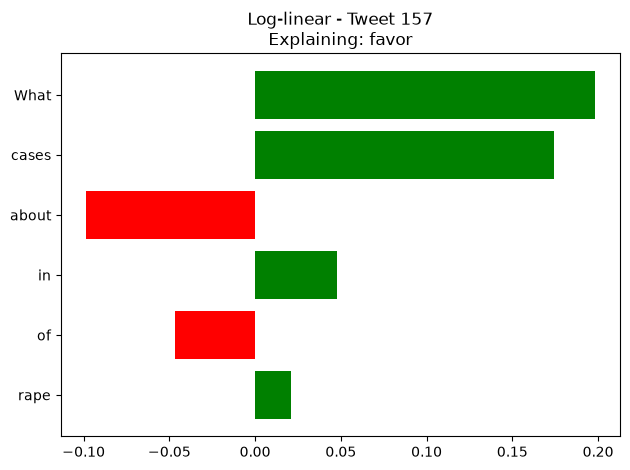


--- Original MLP ---
Prediction: against
Probabilities: [0.2979 0.3563 0.3457]
Explanation: [(np.str_('cases'), 0.05582609393706414), (np.str_('of'), -0.039226122441107694), (np.str_('What'), 0.013102106246167223), (np.str_('rape'), -0.011743707919499677), (np.str_('about'), 0.0034219109838185386), (np.str_('in'), -0.002174217323360019)]


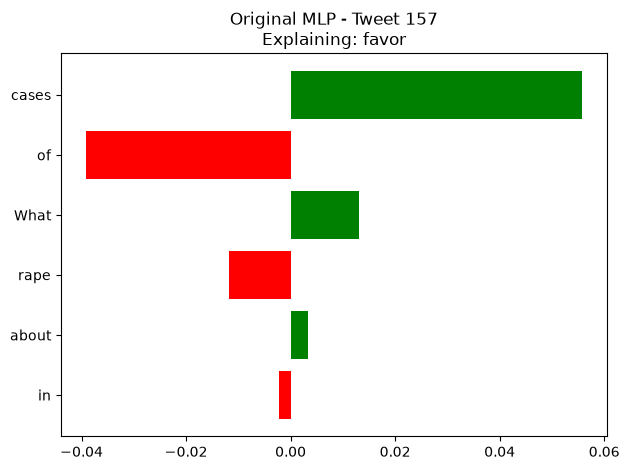


--- Modified MLP ---
Prediction: against
Probabilities: [0.2662 0.3962 0.3376]
Explanation: [(np.str_('cases'), 0.027397136148026743), (np.str_('of'), -0.02634746568245167), (np.str_('rape'), -0.02236069257579077), (np.str_('What'), 0.013555528424254068), (np.str_('in'), 0.005131594107362109), (np.str_('about'), -0.0009690228202166694)]


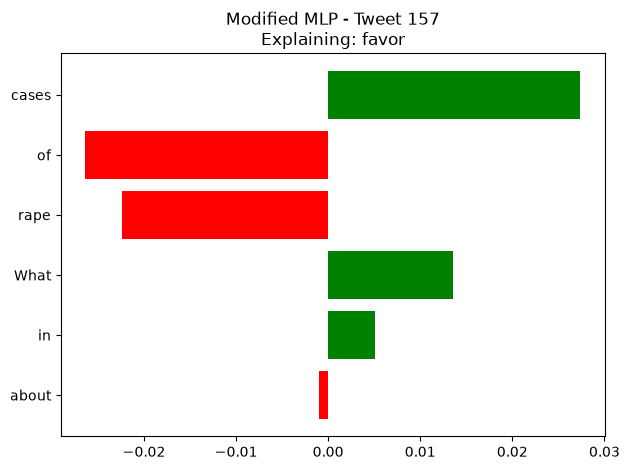

In [27]:
from lime.lime_text import LimeTextExplainer
import numpy as np
import matplotlib.pyplot as plt

class_names = dataset["train"].features["label"].names

explainer = LimeTextExplainer(
    class_names=class_names,
    random_state=42
)

models = {
    "Log-linear": logistic_predict,
    "Original MLP": mlp_predict,
    "Modified MLP": mlp2_predict
}

tweets = [1, 8, 157]

for tweet_id in tweets:

    example = dataset["test"][tweet_id]

    text = example["text"]
    true_label = int(example["label"])

    print(f"\n{'=' * 60}")
    print(f"Tweet {tweet_id}: {text}")
    print(f"True class: {class_names[true_label]}")

    for model_name, predict_fn in models.items():

        probabilities = predict_fn([text])[0]
        predicted_label = int(np.argmax(probabilities))

        # Explain the same target class across all models
        exp = explainer.explain_instance(
            text,
            predict_fn,
            num_features=10,
            num_samples=1000,
            labels=(true_label,)
        )

        print(f"\n--- {model_name} ---")
        print("Prediction:", class_names[predicted_label])
        print("Probabilities:", probabilities.round(4))
        print("Explanation:", exp.as_list(label=true_label))

        fig = exp.as_pyplot_figure(label=true_label)
        plt.title(
            f"{model_name} - Tweet {tweet_id}\n"
            f"Explaining: {class_names[true_label]}"
        )
        plt.tight_layout()
        plt.show()


In [28]:
# Collect cross-validation accuracy measurements
model_scores = {
    "Log-linear": get_all_measurements_for(
        classifiers, "logistic_indicator-enc"
    ).flatten(),

    "MLP": get_all_measurements_for(
        classifiers, "mlp_indicator-enc"
    ).flatten(),

    "Modified MLP": get_all_measurements_for(
        classifiers, "mlp2_indicator-enc"
    ).flatten()
}

# Check the shapes
for name, scores in model_scores.items():
    print(name, scores.shape)

# Bayesian comparisons
results = []

for name_a, name_b in itertools.combinations(model_scores.keys(), 2):

    scores_a = np.asarray(model_scores[name_a], dtype=float)
    scores_b = np.asarray(model_scores[name_b], dtype=float)

    assert scores_a.shape == scores_b.shape, (
        "The models must have the same number of paired measurements."
    )

    posterior = Project1.analysis.BenavoliCorrelatedT(
        scores_a,
        scores_b,
        runs=1,  # Change if you used repeated cross-validation
        names=[name_a, name_b]
    )

    p_a, p_tie, p_b = posterior.probs(0.005)

    results.append({
        "Model A": name_a,
        "Model B": name_b,
        "P(A wins)": p_a,
        "P(Tie)": p_tie,
        "P(B wins)": p_b,
        "Effect Size": posterior.effect_size
    })

df = pd.DataFrame(results)

display(df.round(4))


Log-linear (5,)
MLP (5,)
Modified MLP (5,)


,Model A,Model B,P(A wins),P(Tie),P(B wins),Effect Size
0,Log-linear,MLP,0.0701,0.1210,0.8088,1.4081
1,Log-linear,Modified MLP,0.6547,0.1277,0.2177,-0.6471
2,MLP,Modified MLP,0.8880,0.0530,0.0591,-1.7108


In [30]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

rows = []
for sys_name, runs in classifiers.items():
    acc, prec, rec, f1 = [], [], [], []
    for r, run_data in enumerate(runs):
        for i, (fold, preds) in enumerate(run_data['predictions'].items()):
            gold = [y for _, y in my_cross_validation_sets[r][i]["validation"]]
            acc.append(accuracy_score(gold, preds))
            prec.append(precision_score(gold, preds, average="macro", zero_division=0))
            rec.append(recall_score(gold, preds, average="macro", zero_division=0))
            f1.append(f1_score(gold, preds, average="macro", zero_division=0))
    rows.append({
        "model": sys_name,
        "accuracy": np.mean(acc),
        "precision": np.mean(prec),
        "recall": np.mean(rec),
        "f1": np.mean(f1),
    })

metrics_df = pd.DataFrame(rows)
print(metrics_df.round(4).to_string(index=False))

                 model  accuracy  precision  recall     f1
logistic_indicator-enc    0.5700     0.5450  0.5416 0.5419
     mlp_indicator-enc    0.5865     0.5569  0.5291 0.5332
    mlp2_indicator-enc    0.5552     0.5358  0.4742 0.4627
      logistic_bow-enc    0.5679     0.5432  0.5395 0.5402
           mlp_bow-enc    0.5858     0.5662  0.5213 0.5261
          mlp2_bow-enc    0.5697     0.5682  0.4985 0.4924
    logistic_tfidf-enc    0.5745     0.5699  0.4923 0.4940
         mlp_tfidf-enc    0.5899     0.5644  0.5390 0.5437
        mlp2_tfidf-enc    0.5645     0.5418  0.5060 0.5056
